# Chronic Kidney Disease Prediction
<hr>

## Final Jupyter Notebook, Healthcare
## Original Dataset
## CIS-581-002, Computational Learning
### Avinash Shete, Devidas Ghorpade

### Setup environment/notebook:

In [1]:
# Needed libraries:
# Standard Library:
import math
import pickle
import shelve

# 3rd Party:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display as display
import pandas as pd
import plotly.express as px
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Suppress all warnings - remove for debugging/tuning:
# Note:  Only warning is from cell 34 because resulting plot is only of 1 class!
import warnings
warnings.filterwarnings('ignore')

plt.style.use('fivethirtyeight')
%matplotlib inline
pd.set_option('display.max_columns', 26)

# Track run number for serial execution:
# run_id = # is passed in
run_file = 'hp_results'

# Imputation type for missing numerical values:
# Either random or knn
IMPUTATION = 'knn'

In [2]:
# Load data:
# Note:  Using forward slashes ("/" versus "\") so works on both Windows and Linux/macOS:
data = './Data/chronickidneydisease-uci-400x25.csv'
df= pd.read_csv(data)

# Explore first few rows:
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


### First look at data/dataframe:

In [3]:
# Dimensions (rows, columns) of dataframe:
df.shape

(400, 26)

In [4]:
# Show overview of dataframe columns:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [5]:
# Show number of unique values per column:
df.nunique()

id                400
age                76
bp                 10
sg                  5
al                  6
su                  6
rbc                 2
pc                  2
pcc                 2
ba                  2
bgr               146
bu                118
sc                 84
sod                34
pot                40
hemo              115
pcv                44
wc                 92
rc                 49
htn                 2
dm                  5
cad                 3
appet               2
pe                  2
ane                 2
classification      3
dtype: int64

In [6]:
# Examine descriptive statistics for each column - average, standard deviation, quartiles, and more:
df.describe()

,id,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,400.000000,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,199.500000,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,115.614301,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,0.000000,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,99.750000,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,199.500000,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,299.250000,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,399.000000,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


### Data Preprocessing:

In [7]:
# Remove id column:
df.drop('id', axis=1, inplace=True)

In [8]:
# Rename column names to make it more user-friendly:
df.columns = ['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar', 'red_blood_cells', 'pus_cell',
              'pus_cell_clumps', 'bacteria', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
              'potassium', 'hemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count',
              'hypertension', 'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'peda_edema',
              'anemia', 'class']

In [9]:
# Again look at first few rows to see column name changes:
df.head()

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,hemoglobin,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


In [10]:
# Generate summary statistics of numerical columns, including standard deviation and quartiles:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,hemoglobin
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [11]:
# Show overview of dataframe columns:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  hemoglobin               3

In [12]:
# Convert relevant columns to numerical type:
df['packed_cell_volume'] = pd.to_numeric(df['packed_cell_volume'], errors='coerce')
df['white_blood_cell_count'] = pd.to_numeric(df['white_blood_cell_count'], errors='coerce')
df['red_blood_cell_count'] = pd.to_numeric(df['red_blood_cell_count'], errors='coerce')

In [13]:
# Confirm changes - note the 3 columns data types are now floating point:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  hemoglobin               3

In [14]:
# Collect categorical and numerical columns:
cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']

In [15]:
# Review unique values in categorical columns to check for missing values (nans):
def display_cols(cols, val_title='Values', op='unique'):
    colsize = max(len(col) for col in cols)
    trailing = int(colsize * 1.5)
    print(f'{"Column:":>{colsize}} | {val_title}:')
    print('-' * colsize, '|', '-' * trailing)
    for col in sorted(cols):        
        output = res if isinstance(res := getattr(df[col], op)(), int) else ', '.join(map(str, res)) 
        print(f'{col:>{colsize}} | {output}')

display_cols(cat_cols)

                Column: | Values:
----------------------- | ----------------------------------
                 anemia | no, yes, nan
               appetite | good, poor, nan
               bacteria | notpresent, present, nan
                  class | ckd, ckd	, notckd
coronary_artery_disease | no, yes, 	no, nan
      diabetes_mellitus | yes, no,  yes, 	no, 	yes, nan
           hypertension | yes, no, nan
             peda_edema | no, yes, nan
               pus_cell | normal, abnormal, nan
        pus_cell_clumps | notpresent, present, nan
        red_blood_cells | nan, normal, abnormal


In [16]:
# Remove extra whitespace:
for dfcol in ('diabetes_mellitus', 'coronary_artery_disease', 'class'):
    df[dfcol] = df[dfcol].str.strip()

In [17]:
# Re-check:
display_cols(cat_cols)

# Note the nans - more cleanup to do...

                Column: | Values:
----------------------- | ----------------------------------
                 anemia | no, yes, nan
               appetite | good, poor, nan
               bacteria | notpresent, present, nan
                  class | ckd, notckd
coronary_artery_disease | no, yes, nan
      diabetes_mellitus | yes, no, nan
           hypertension | yes, no, nan
             peda_edema | no, yes, nan
               pus_cell | normal, abnormal, nan
        pus_cell_clumps | notpresent, present, nan
        red_blood_cells | nan, normal, abnormal


### Visually Explore Data:

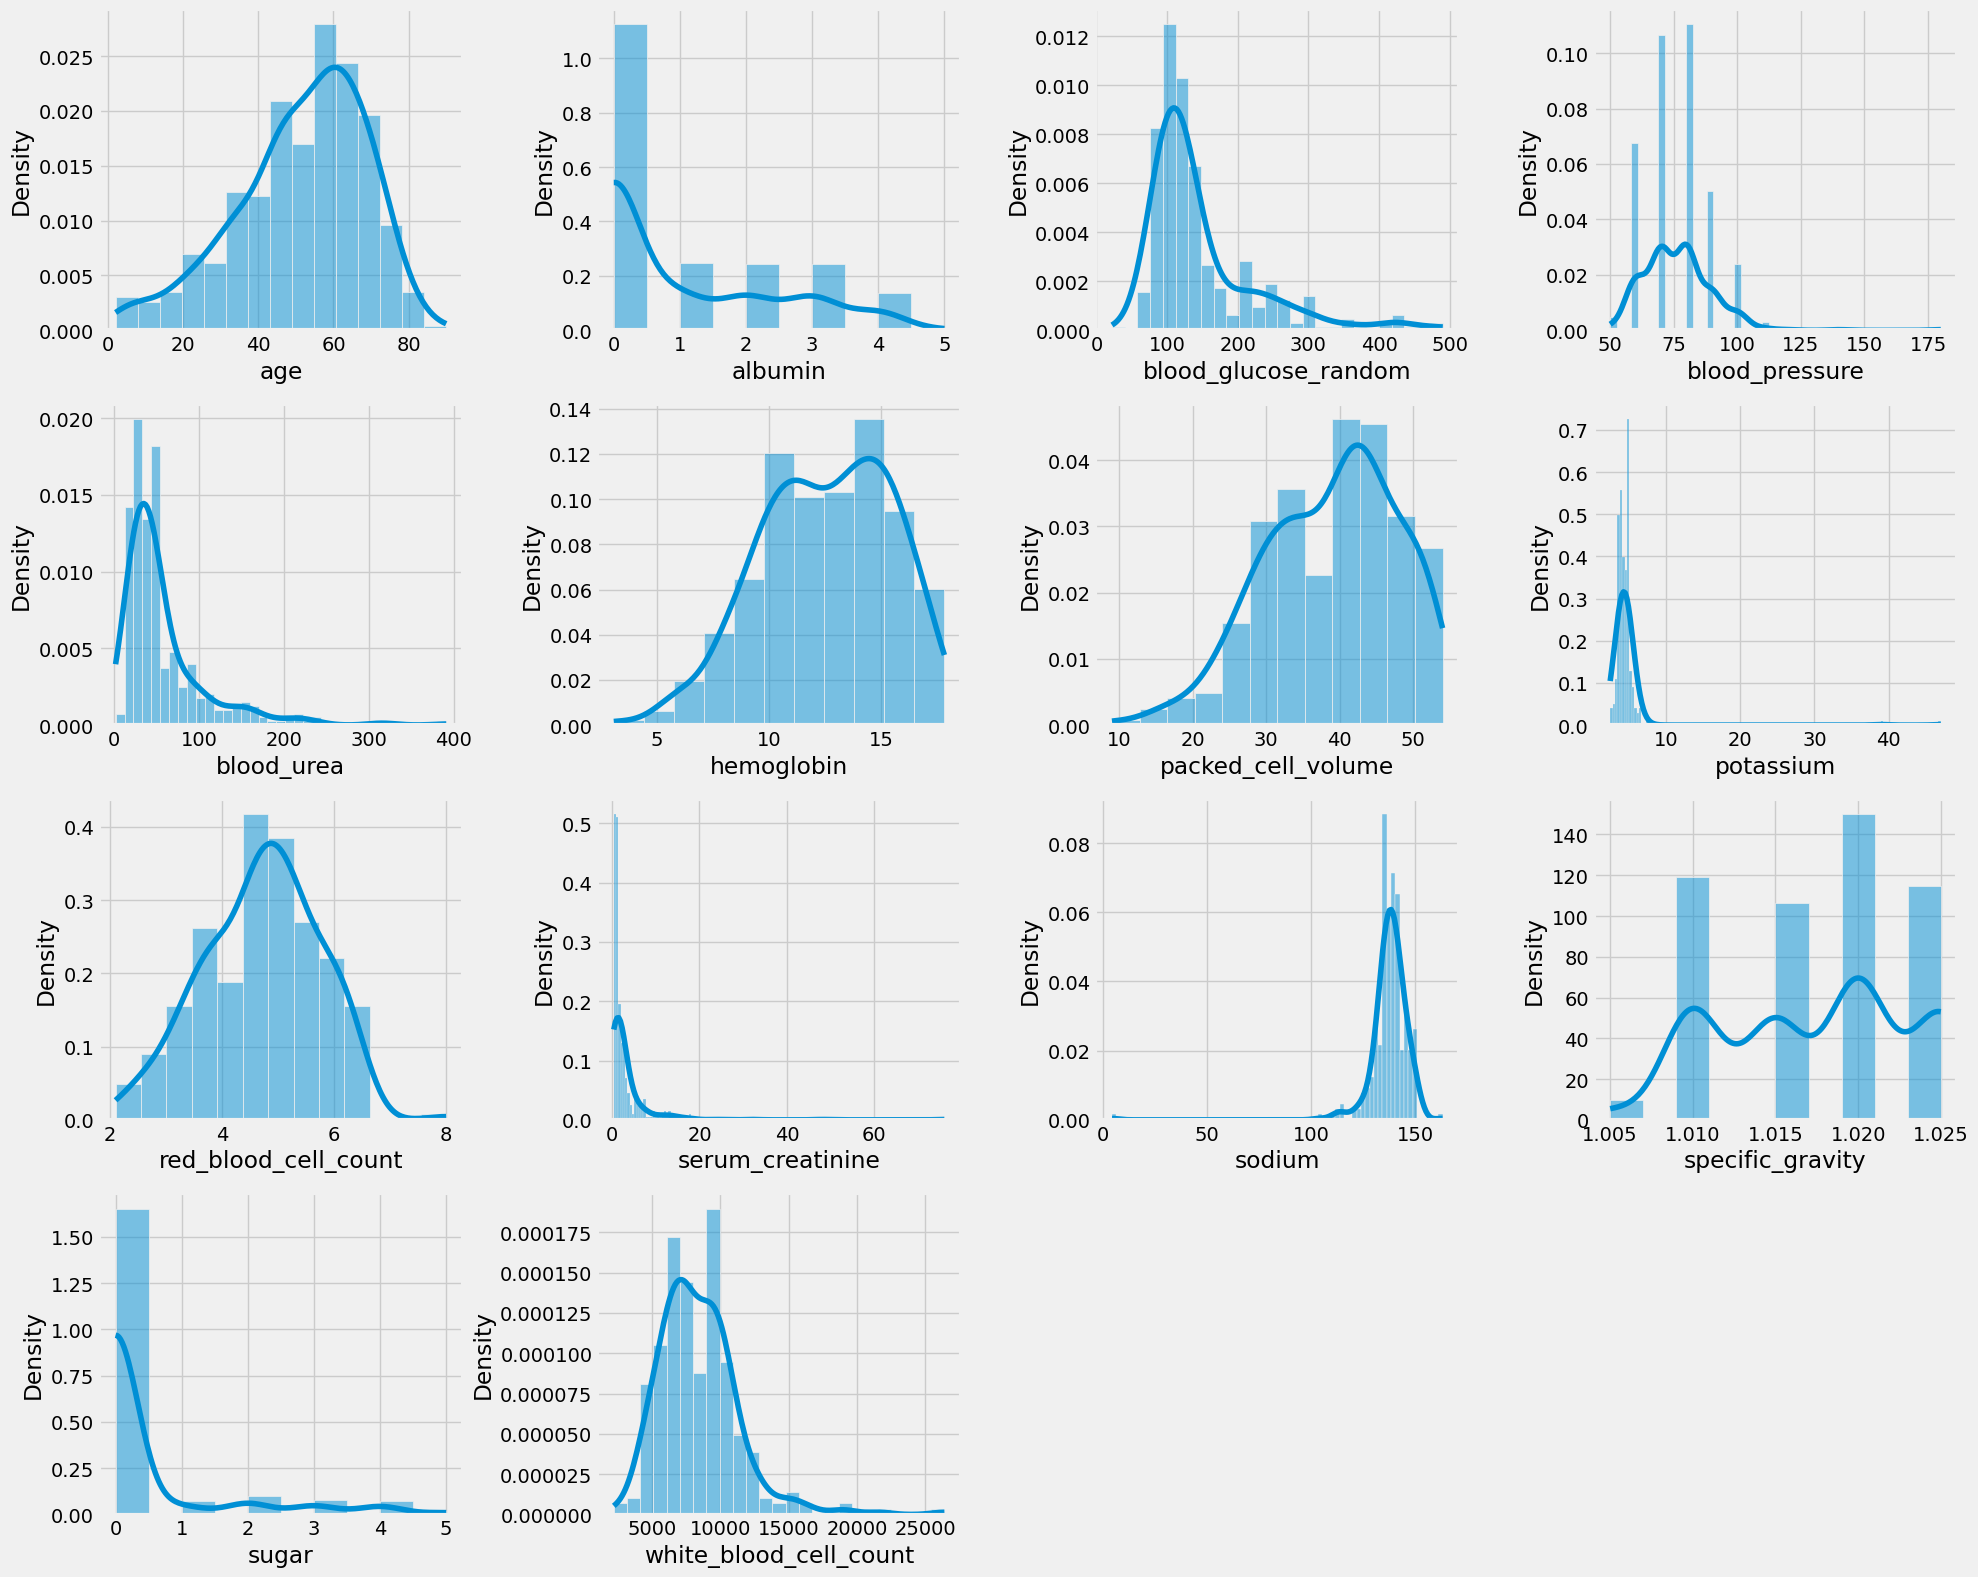

In [18]:
# Visualize numerical features distribution:

# Determine number of plots and subplot grid:
num_plots = len(num_cols)
cols = 4
rows = math.ceil(num_plots / cols)

cell_width = 5  # inches per subplot column
cell_height = 4  # inches per subplot row

# Scale figure size with number of rows
plt.figure(figsize=(cols * cell_width, rows * cell_height))

for i, column in enumerate(sorted(num_cols), 1):
    ax = plt.subplot(rows, cols, i)
    # Try to use histplot instead of deprecated distplot:
    # sns.histplot(df[column], kde=True, ax=ax)
    # sns.distplot(df[column])
    sns.histplot(df[column], kde=True, stat="density", element="bars", ax=ax)
    # Optional styling:
    # sns.rugplot(df[column], ax=ax, color="black", height=0.05)
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  hemoglobin               3

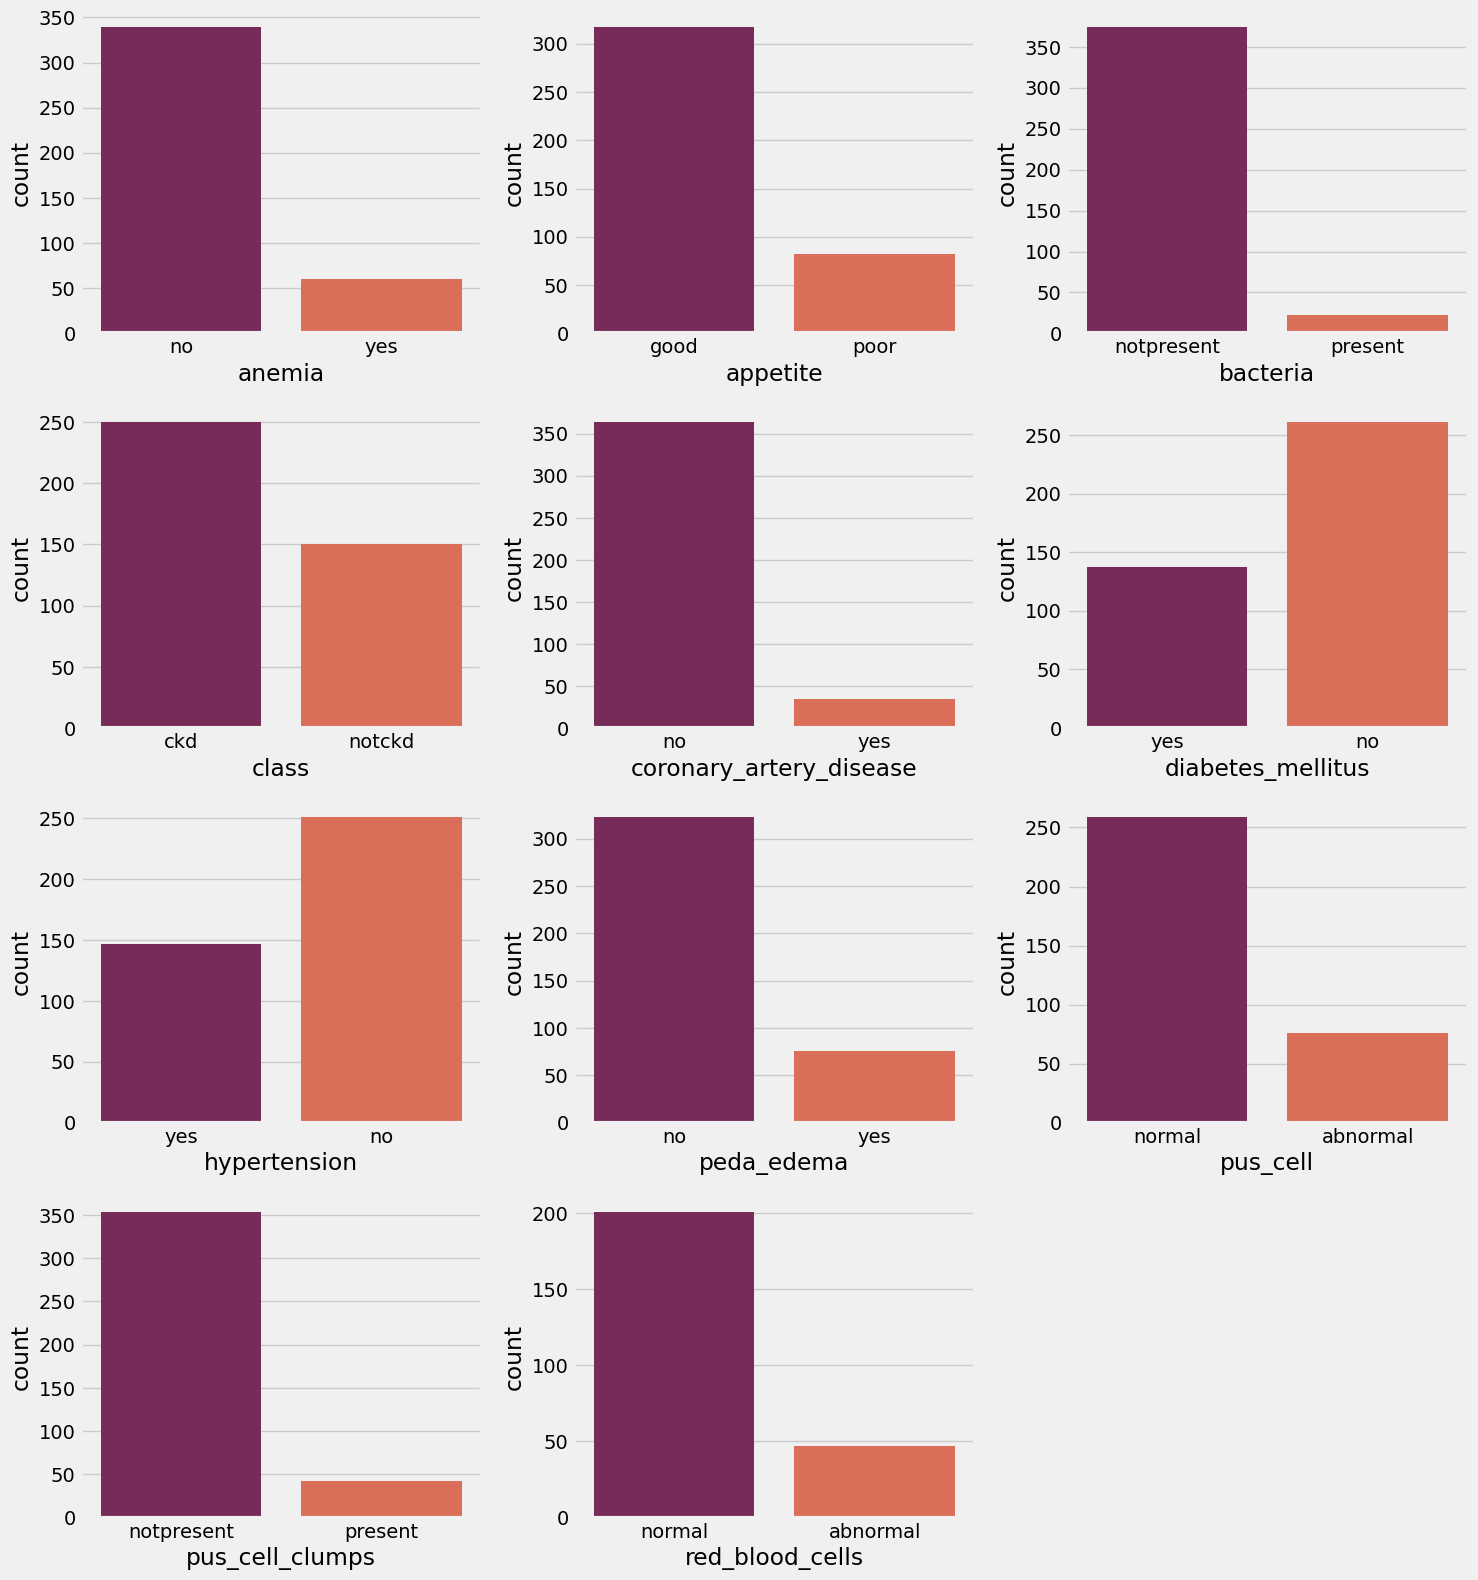

In [20]:
# Visualize categorical column data distribution:

# Determine number of plots and subplot grid:
num_plots = len(cat_cols)
cols = 3
rows = math.ceil(num_plots / cols)

cell_width = 5  # inches per subplot column
cell_height = 4  # inches per subplot row

plt.figure(figsize=(cols * cell_width, rows * cell_height))

for i, column in enumerate(sorted(cat_cols), 1):
    ax = plt.subplot(rows, cols, i)
    sns.countplot(data=df, x=column, hue=column, palette='rocket', legend=False, ax=ax)
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

In [21]:
# Remap values - patients with Chronic Kidney Disease = 0, without = 1:
df['class'] = df['class'].map({'ckd': 1, 'notckd': 0})
df['class'] = pd.to_numeric(df['class'], errors='coerce')
# Note:  Doing this after plotting as the plot looks better before converting it to a numeric column

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  hemoglobin               3

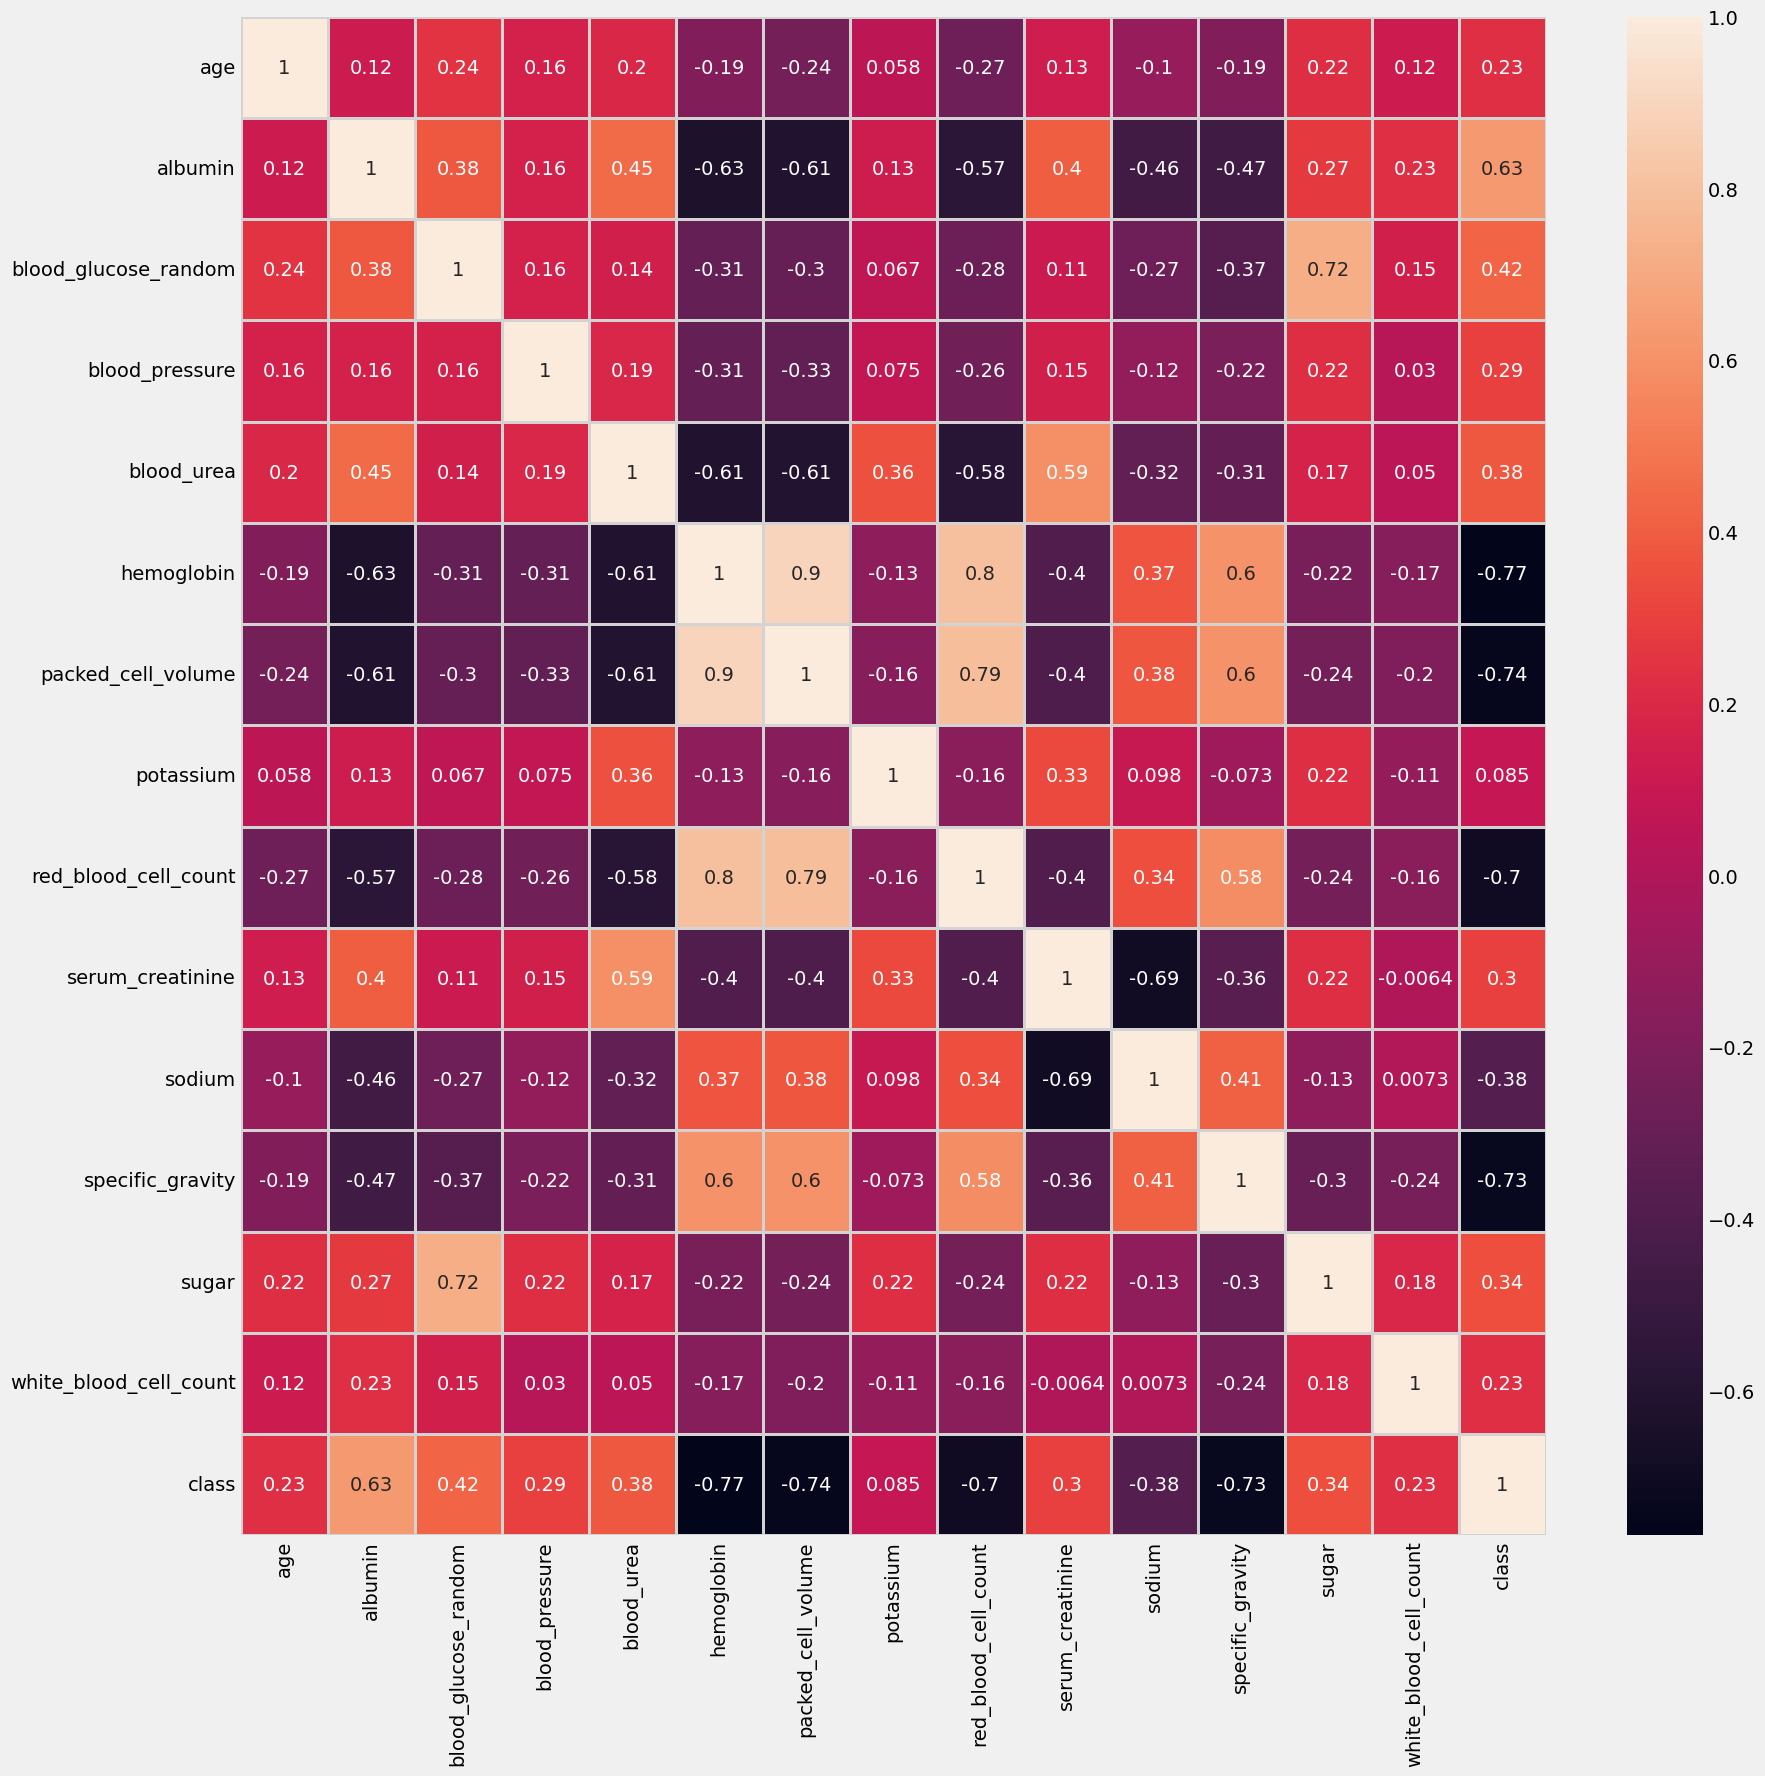

In [23]:
# Heatmap of data:

cell_size = 0.75 # in inches — adjust to make text readable
columns = df.shape[1]
rows = columns  # square correlation matrix

width = cell_size * columns
height = cell_size * rows

# Create new dataframe to alphabetize columns:
dfcor = df.copy()
outcome_list = ['class']
cor_cols = sorted(num_cols) + outcome_list
dfcor = dfcor[cor_cols]

plt.figure(figsize=(width, height))
sns.heatmap(dfcor.corr(numeric_only=True), annot=True, linewidths=2, linecolor='lightgrey')

plt.show()

### Visual Data Analysis:

In [24]:
# Functions to plot data:

# Create a violin plot to contrast each column for those with and without CKD
# Include a box plot within the violin plot (box=True)
def violin(col):
    fig = px.violin(df, y=col, x='class', color='class', box=True, template='plotly_dark',
                    color_discrete_map={0: '#636EFA', 1: '#EF553B'})
    fig.update_layout(legend_traceorder='reversed')
    return fig.show()

# Create a Kernel Density Estimation plot contrasting those with and without CKD
# Allows visualizing the probability density function (PDF) of a continuous variable
# In other words - this visually shows the distribution of the column data
def kde(col):
    grid = sns.FacetGrid(df, hue='class', height=6, aspect=2)
    # grid.map(sns.kdeplot, col, warn_singular=False)
    grid.map(sns.kdeplot, col)
    grid.add_legend()

# Create a scatter plot contrasting pairs of columns for those with and without CKD
# This allows visualizing the relationship and correlation between pairs of columns
# while simultaneously differentiating (via color) those with and without CKD
def scatter(col1, col2):
    fig = px.scatter(df, x=col1, y=col2, color='class', template='plotly_dark',
                     color_discrete_map={0: '#636EFA', 1: '#EF553B'})
    fig.update_layout(legend_traceorder='reversed')
    return fig.show()

In [25]:
violin('red_blood_cell_count')

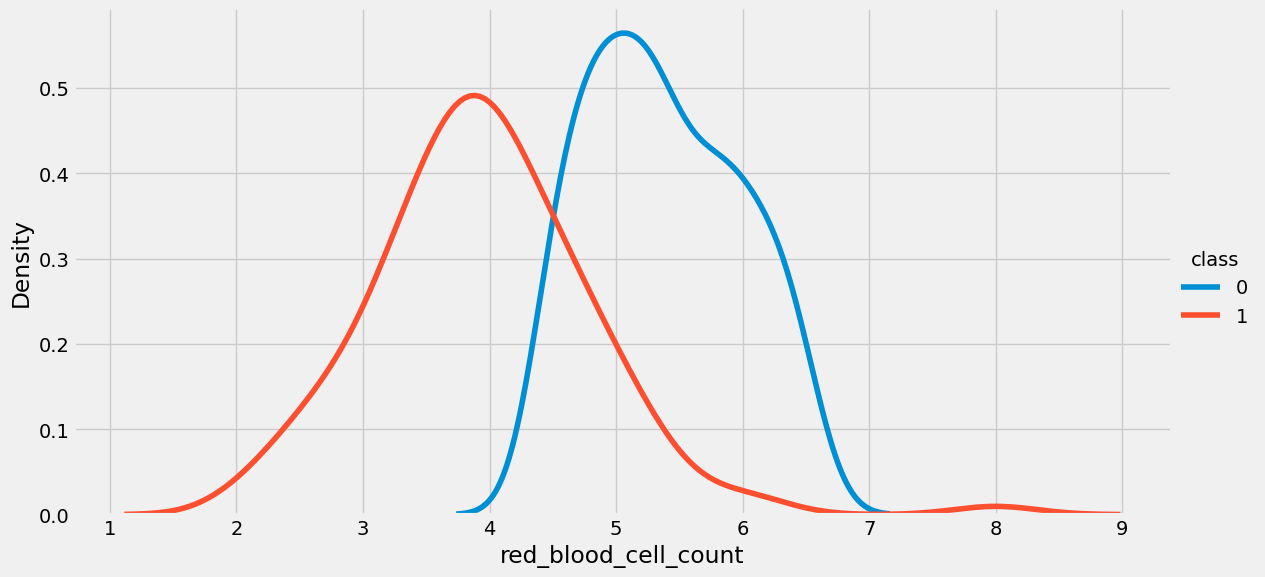

In [26]:
kde('red_blood_cell_count')

In [27]:
violin('white_blood_cell_count')

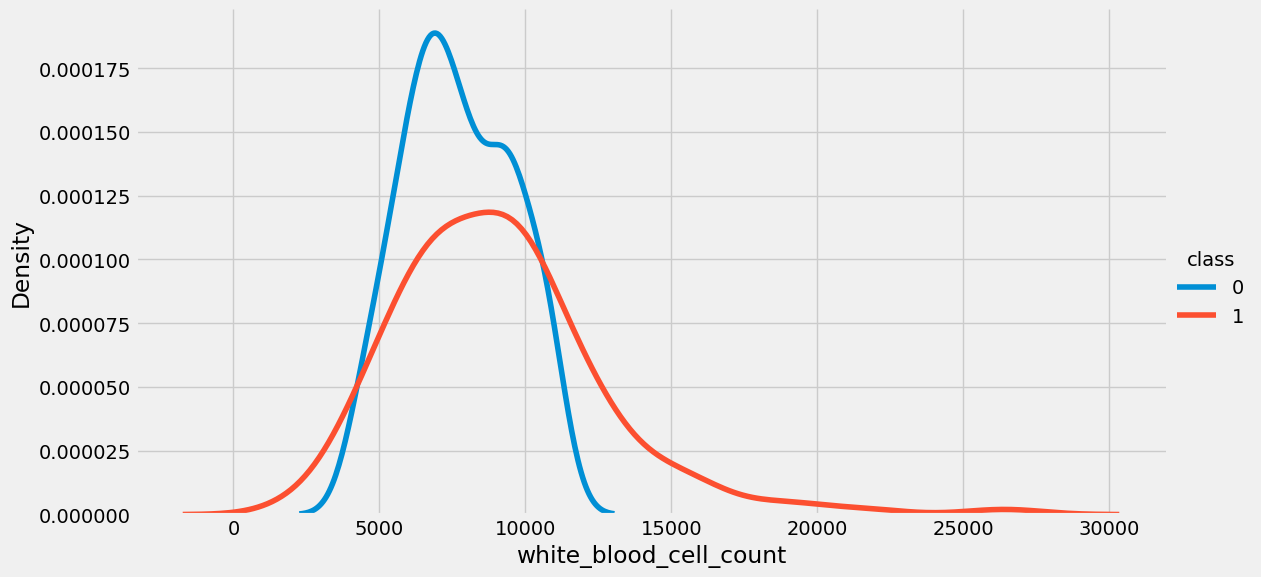

In [28]:
kde('white_blood_cell_count')

In [29]:
violin('packed_cell_volume')

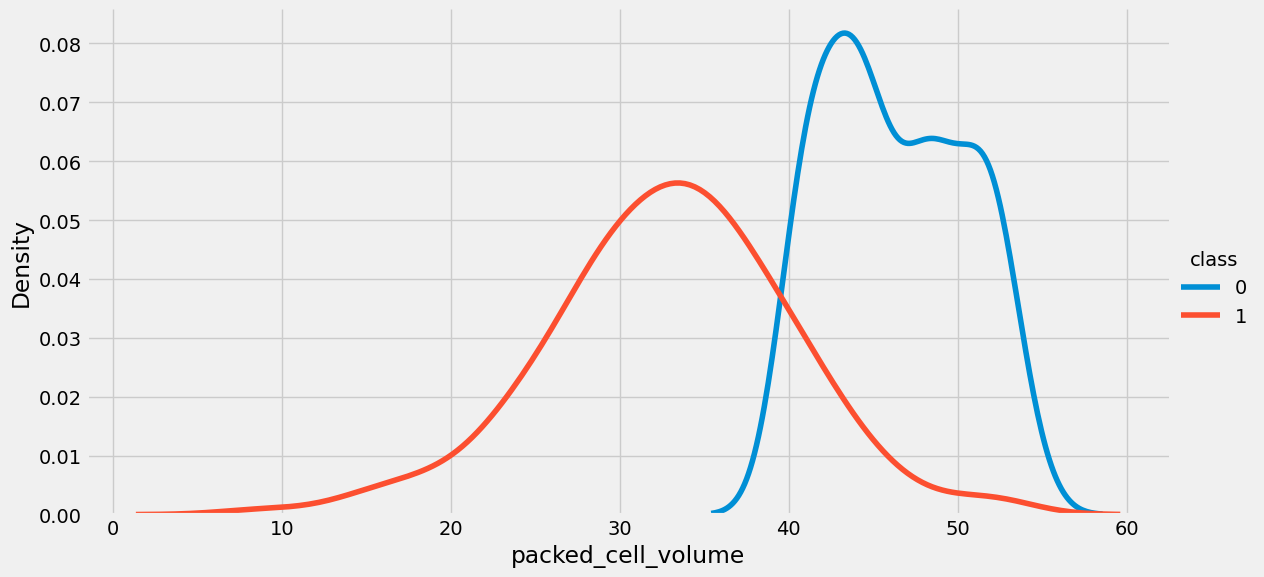

In [30]:
kde('packed_cell_volume')

In [31]:
violin('hemoglobin')

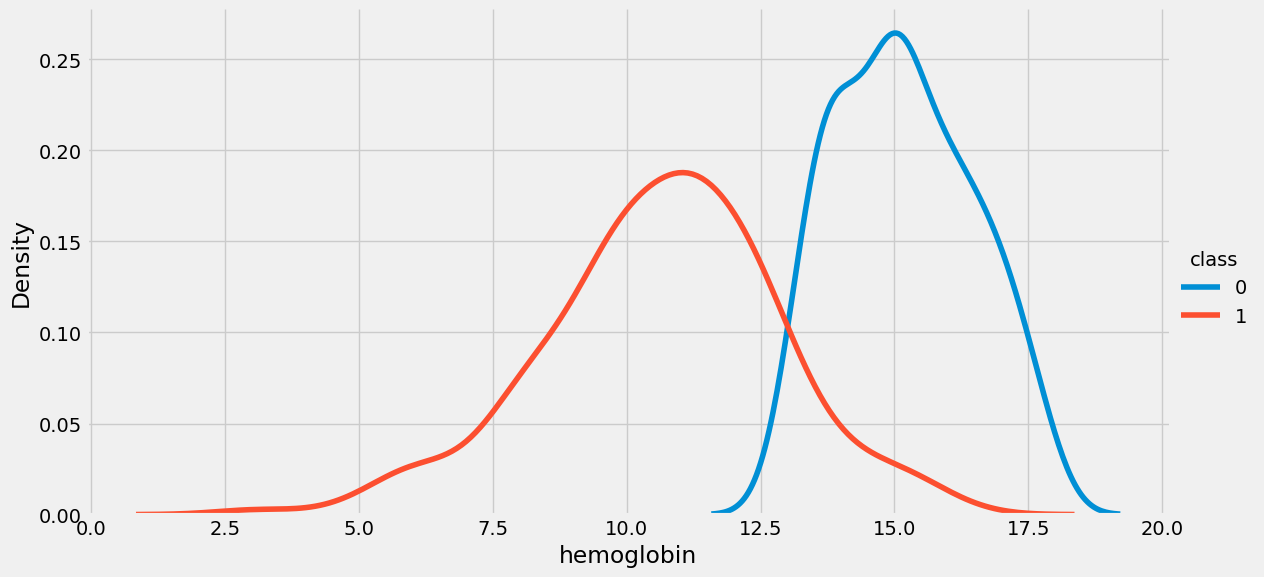

In [32]:
kde('hemoglobin')

In [33]:
violin('albumin')

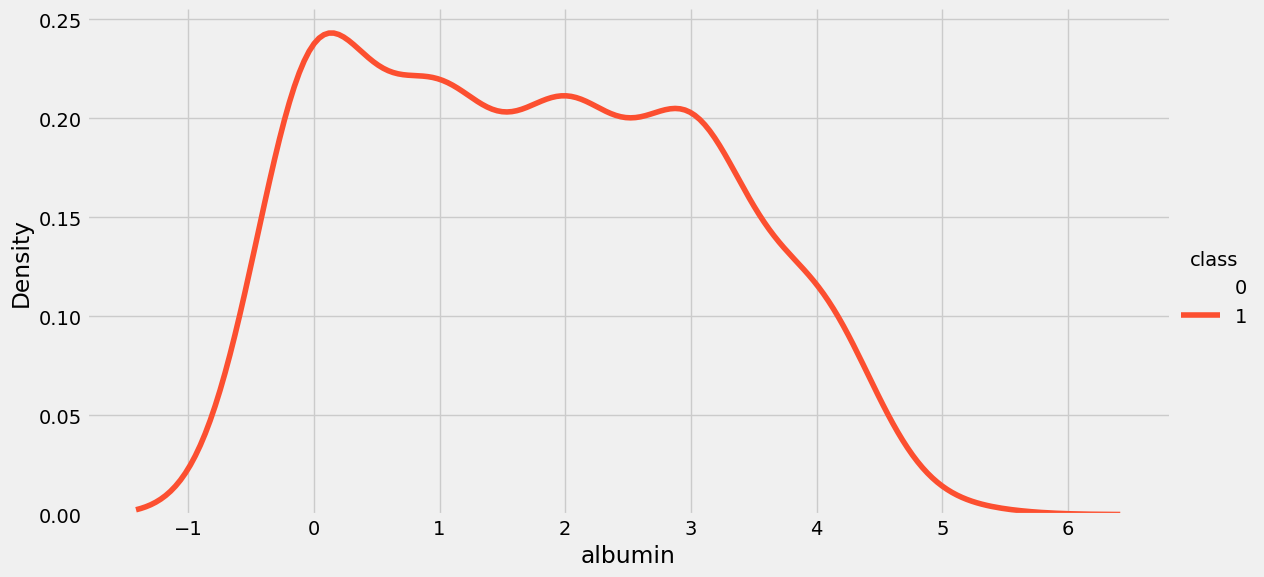

In [34]:
kde('albumin')

In [35]:
violin('blood_glucose_random')

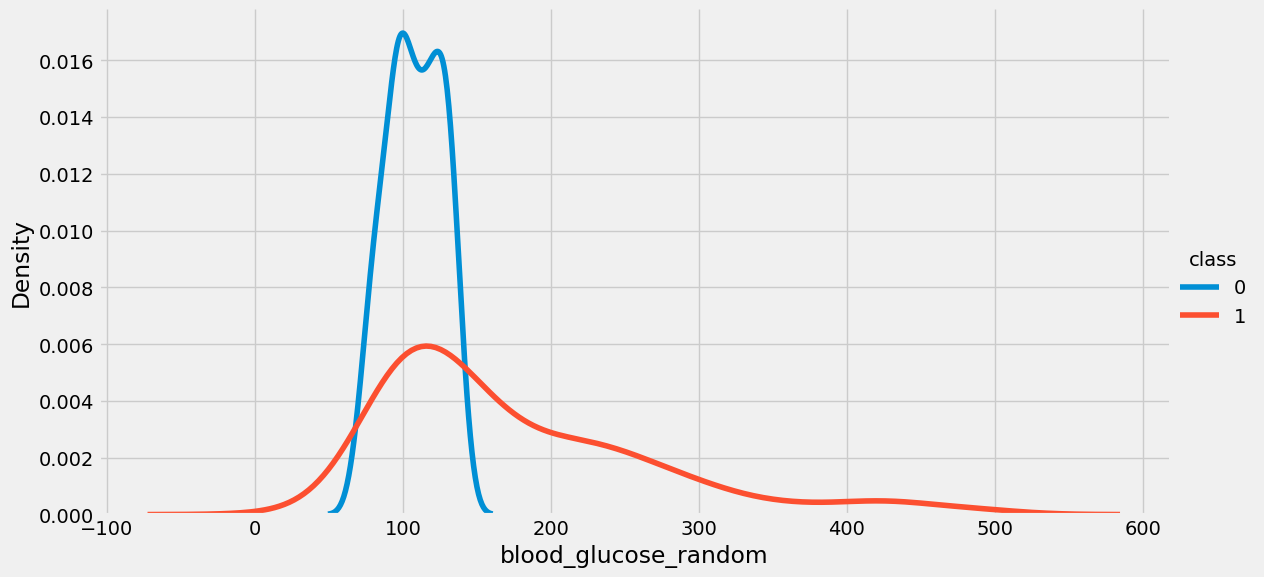

In [36]:
kde('blood_glucose_random')

In [37]:
violin('sodium')

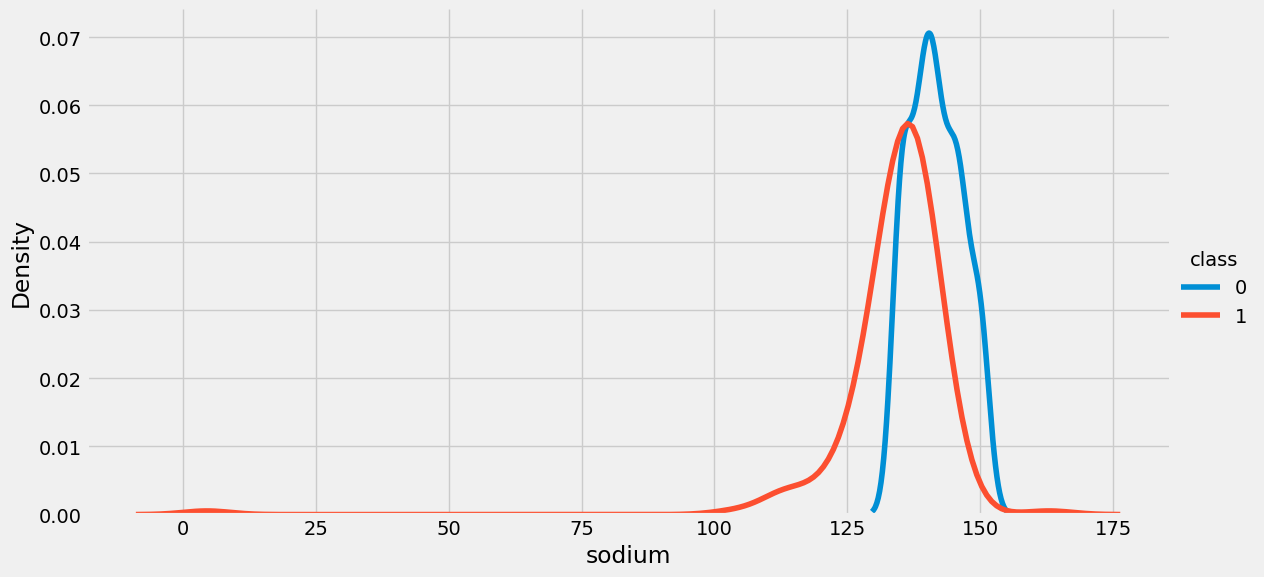

In [38]:
kde('sodium')

In [39]:
violin('blood_urea')

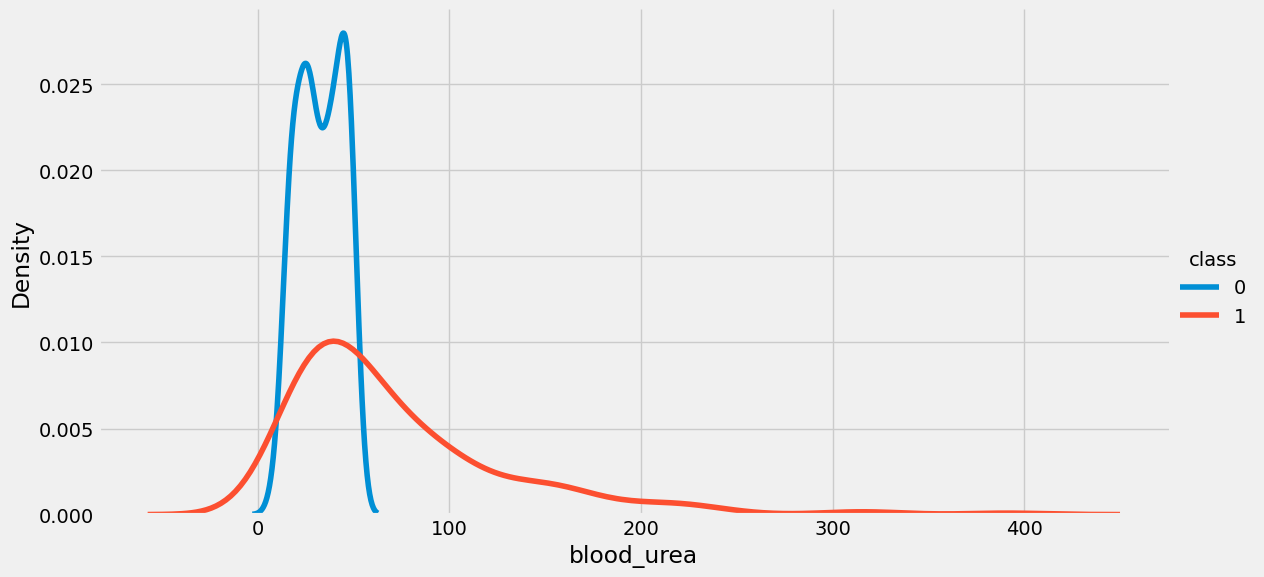

In [40]:
kde('blood_urea')

In [41]:
violin('specific_gravity')

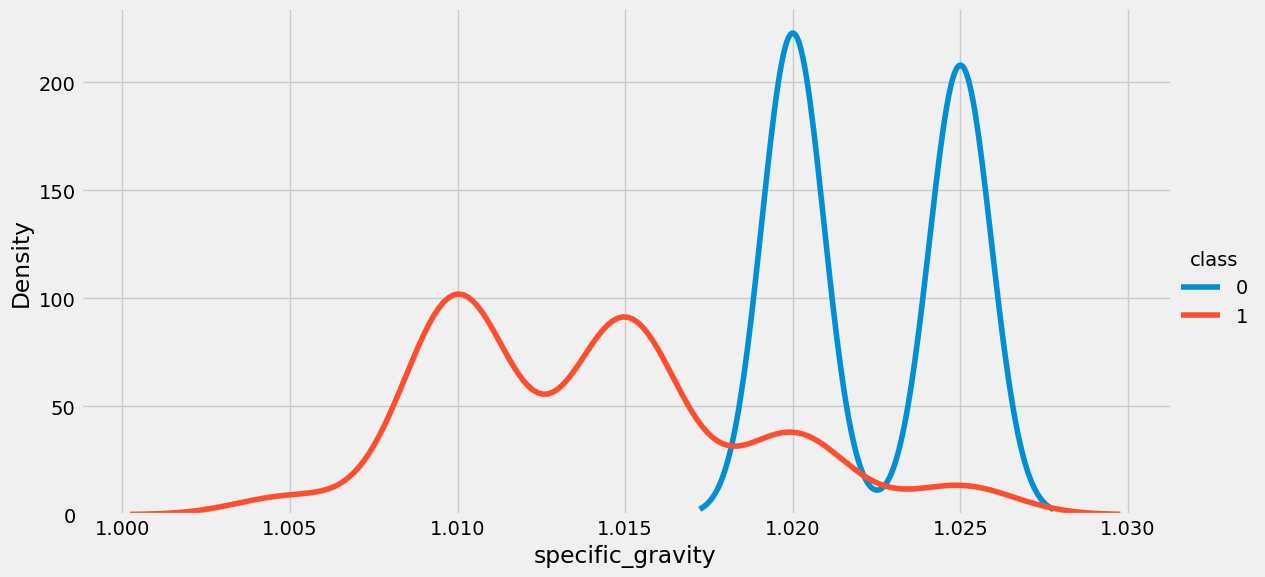

In [42]:
kde('specific_gravity')

In [43]:
scatter('hemoglobin', 'packed_cell_volume')

In [44]:
scatter('red_blood_cell_count', 'packed_cell_volume')

In [45]:
scatter('red_blood_cell_count', 'albumin')

In [46]:
scatter('sugar', 'blood_glucose_random')

In [47]:
scatter('packed_cell_volume','blood_urea')

In [48]:
px.bar(df, x="specific_gravity", y="packed_cell_volume", color='class', barmode='group', template = 'plotly_dark', height = 400)

In [49]:
px.bar(df, x="specific_gravity", y="albumin", color='class', barmode='group', template = 'plotly_dark', height = 400)

In [50]:
px.bar(df, x="blood_pressure", y="packed_cell_volume", color='class', barmode='group', template = 'plotly_dark', height = 400)

In [51]:
px.bar(df, x="blood_pressure", y="hemoglobin", color='class', barmode='group', template = 'plotly_dark', height = 400)

### Data Cleaning:

In [52]:
# Check for null values:
df.isna().sum().sort_values(ascending = False)

red_blood_cells            152
red_blood_cell_count       131
white_blood_cell_count     106
potassium                   88
sodium                      87
packed_cell_volume          71
pus_cell                    65
hemoglobin                  52
sugar                       49
specific_gravity            47
albumin                     46
blood_glucose_random        44
blood_urea                  19
serum_creatinine            17
blood_pressure              12
age                          9
pus_cell_clumps              4
bacteria                     4
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
peda_edema                   1
anemia                       1
class                        0
dtype: int64

In [53]:
df[num_cols].isnull().sum()

age                         9
blood_pressure             12
specific_gravity           47
albumin                    46
sugar                      49
blood_glucose_random       44
blood_urea                 19
serum_creatinine           17
sodium                     87
potassium                  88
hemoglobin                 52
packed_cell_volume         71
white_blood_cell_count    106
red_blood_cell_count      131
dtype: int64

In [54]:
df[cat_cols].isnull().sum()

red_blood_cells            152
pus_cell                    65
pus_cell_clumps              4
bacteria                     4
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
peda_edema                   1
anemia                       1
class                        0
dtype: int64

In [55]:
# For filling null values, we will use two methods, random sampling for higher null values
# and mean/mode sampling for lower null values:

def random_value_imputation(feature):
    random_sample = df[feature].dropna().sample(df[feature].isna().sum())
    random_sample.index = df[df[feature].isnull()].index
    df.loc[df[feature].isnull(), feature] = random_sample
    
def impute_mode(feature):
    mode = df[feature].mode()[0]
    df[feature] = df[feature].fillna(mode)

def knn_impute_numerical(feature):
    knn_imputer = KNNImputer(n_neighbors=10)
    df[feature] = knn_imputer.fit_transform(df[[feature]])

In [56]:
# Filling num_cols null values:

if IMPUTATION == 'random':
    # Use random sampling method:
    print('Using random value imputation...')
    for col in num_cols:
        random_value_imputation(col)
else:
    # Use KNN sampling method:
    print('Using KNN value imputation...')
    for col in num_cols:
        knn_impute_numerical(col)

Using KNN value imputation...


In [57]:
df[num_cols].isnull().sum()

age                       0
blood_pressure            0
specific_gravity          0
albumin                   0
sugar                     0
blood_glucose_random      0
blood_urea                0
serum_creatinine          0
sodium                    0
potassium                 0
hemoglobin                0
packed_cell_volume        0
white_blood_cell_count    0
red_blood_cell_count      0
dtype: int64

In [58]:
# Filling "red_blood_cells" and "pus_cell" using random sampling method
# and rest of cat_cols using mode imputation:
random_value_imputation('red_blood_cells')
random_value_imputation('pus_cell')

for col in cat_cols:
    impute_mode(col)

In [59]:
df[cat_cols].isnull().sum()

red_blood_cells            0
pus_cell                   0
pus_cell_clumps            0
bacteria                   0
hypertension               0
diabetes_mellitus          0
coronary_artery_disease    0
appetite                   0
peda_edema                 0
anemia                     0
class                      0
dtype: int64

### Feature Encoding:

In [60]:
display_cols(cat_cols, val_title='Categories', op='nunique')

                Column: | Categories:
----------------------- | ----------------------------------
                 anemia | 2
               appetite | 2
               bacteria | 2
                  class | 2
coronary_artery_disease | 2
      diabetes_mellitus | 2
           hypertension | 2
             peda_edema | 2
               pus_cell | 2
        pus_cell_clumps | 2
        red_blood_cells | 2


### Label Encoding:

In [61]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

In [62]:
df.head()

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,hemoglobin,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,peda_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,0,1,0,0,121.000000,36.0,1.2,137.528754,4.627244,15.4,44.0,7800.0,5.200000,1,1,0,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,148.036517,18.0,0.8,137.528754,4.627244,11.3,38.0,6000.0,4.707435,0,0,0,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.000000,53.0,1.8,137.528754,4.627244,9.6,31.0,7500.0,4.707435,0,1,0,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.000000,56.0,3.8,111.000000,2.500000,11.2,32.0,6700.0,3.900000,1,0,0,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.000000,26.0,1.4,137.528754,4.627244,11.6,35.0,7300.0,4.600000,0,0,0,0,0,0,1


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      400 non-null    float64
 1   blood_pressure           400 non-null    float64
 2   specific_gravity         400 non-null    float64
 3   albumin                  400 non-null    float64
 4   sugar                    400 non-null    float64
 5   red_blood_cells          400 non-null    int64  
 6   pus_cell                 400 non-null    int64  
 7   pus_cell_clumps          400 non-null    int64  
 8   bacteria                 400 non-null    int64  
 9   blood_glucose_random     400 non-null    float64
 10  blood_urea               400 non-null    float64
 11  serum_creatinine         400 non-null    float64
 12  sodium                   400 non-null    float64
 13  potassium                400 non-null    float64
 14  hemoglobin               4

<a id = '5.0'></a>
<p style = "font-size : 45px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #f9b208; border-radius: 5px 5px;"><strong>Model Building</strong></p> 

In [64]:
ind_col = [col for col in df.columns if col != 'class']
dep_col = 'class'

X = df[ind_col]
y = df[dep_col]

In [65]:
# Split data into training and test sets:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 0)

In [66]:
# Build confusion matrix results dataframe:
def get_cm_results(cm):
    # cm is the result of sklearn.metrics.confusion_matrix(y_test, classifier.predict(X_test))
    tn, fp, fn, tp = cm.ravel()
    data = [
        {'Result': 'True Positive', 'Number': tp,
         'Description': 'Actual occurrence, correctly predicted'},
        {'Result': 'True Negative', 'Number': tn,
         'Description': 'Non-occurrence, correctly predicted'},
        {'Result': 'False Negative', 'Number': fn,
         'Description': 'Actual occurrence, incorrectly predicted (Type II error)'},
        {'Result': 'False Positive', 'Number': fp,
         'Description': 'Non-occurrence, incorrectly predicted (Type I error)'},
    ]
    return pd.DataFrame(data).style.set_properties(
        subset=['Description'], **{'text-align': 'left'}
    ).hide(axis='index')


# Build confusion matrix metrics dataframe:
def get_cm_metrics(cm):
    # cm is the result of sklearn.metrics.confusion_matrix(y_test, classifier.predict(X_test))
    tn, fp, fn, tp = cm.ravel()
    prec_val = tp/(tp + fp)
    rec_val = tp/(tp + fn)
    data = [
        {'Metric': 'Accuracy', 'Value': (tp + tn)/(tp + tn + fp + fn),
         'Description': 'How often is classifier correct'},
        {'Metric': 'Precision', 'Value': prec_val,
         'Description': 'How often is TP correctly predicted (% of correct positives)'},
        {'Metric': 'Recall', 'Value': rec_val,
         'Description': 'How often is actual occurrence correctly predicted'},
        {'Metric': 'F1-Score', 'Value': (2 * prec_val * rec_val)/(prec_val + rec_val),
         'Description': 'Account for both precision and recall using harmonic mean'},
        {'Metric': 'Misclassification', 'Value': (fp + fn)/(tp + tn + fp + fn),
         'Description': 'How often is classifier wrong'},
        {'Metric': 'NPV', 'Value': tn/(tn + fn),
         'Description': 'How often is TN correctly predicted (% of correct negatives)'},
        {'Metric': 'FPR', 'Value': fp/(tn + fp),
         'Description': 'How often is non-occurrence falsely predicted'},
        {'Metric': 'Specificity', 'Value': tn/(tn + fp),
         'Description': 'How often is actual non-occurrence correctly predicted'},
        {'Metric': 'Prevalence', 'Value': (fn + tp)/(tp + tn + fp + fn),
         'Description': 'How often does actually occur in sample'},
    ]
    return pd.DataFrame(data).style.set_properties(
        subset=['Description'], **{'text-align': 'left'}
    ).format({'Value': '{:.2%}'}).hide(axis='index')

# Plot confusion matrix heatmap:
def cm_heatmap(cm):
    classes = ['No CKD', 'CKD']
    df_cm = pd.DataFrame(cm, index=classes, columns=classes)
    
    # Flip horizontally and vertically
    df_cm = df_cm.iloc[::-1, ::-1]
    
    plt.figure(figsize=(5,4))
    sns.heatmap(df_cm, annot=True, fmt='d', cmap='coolwarm_r',
                linewidths=0.5, cbar_kws={'label': 'Count'})
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix Heatmap')
    return plt.show()

# Track results by saving/serializing:
def save_cm(cm, model):
    # cm is the result of sklearn.metrics.confusion_matrix(y_test, classifier.predict(X_test))
    tn, fp, fn, tp = cm.ravel()
    prec_val = tp/(tp + fp)
    rec_val = tp/(tp + fn)
    accuracy = (tp + tn)/(tp + tn + fp + fn)
    precision = prec_val
    recall = rec_val
    f1_score = (2 * prec_val * rec_val)/(prec_val + rec_val)
    misclassification = (fp + fn)/(tp + tn + fp + fn)
    npv = tn/(tn + fn)
    fpr = fp/(tn + fp)
    specificity = tn/(tn + fp)
    prevalence = (fn + tp)/(tp + tn + fp + fn)
    model_name = model if isinstance(model, str) else model.__class__.__name__
    imputation = IMPUTATION

    # Safety check in case Notebook run directly:
    run_id = globals().get('run_id', 0)
    with shelve.open(run_file) as db:
        db[f'{run_id}/{model_name}'] = dict(
            true_positive=tp, true_negative=tn, false_negative=fn, false_postive=fp,
            accuracy=accuracy, precision=precision, recall=recall, f1_score=f1_score,
            misclassification=misclassification, npv=npv, fpr=fpr, specificity=specificity,
            prevalence=prevalence, imputation=imputation
        )

<a id = '5.2'></a>
<p style = "font-size : 25px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #fbc6a4; border-radius: 5px 5px;"><strong>Decision Tree Classifier</strong></p> 

In [67]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)

# Accuracy score, confusion matrix and classification report of decision tree:
dtc_acc = accuracy_score(y_test, dtc.predict(X_test))

print(f"Training Accuracy of Decision Tree Classifier is {accuracy_score(y_train, dtc.predict(X_train))}")
print(f"Test Accuracy of Decision Tree Classifier is {dtc_acc} \n")

cm = confusion_matrix(y_test, dtc.predict(X_test))
print(f"Confusion Matrix :- \n{cm}\n")
print(f"Classification Report :- \n {classification_report(y_test, dtc.predict(X_test))}")

Training Accuracy of Decision Tree Classifier is 1.0
Test Accuracy of Decision Tree Classifier is 0.9416666666666667 

Confusion Matrix :- 
[[45  3]
 [ 4 68]]

Classification Report :- 
               precision    recall  f1-score   support

           0       0.92      0.94      0.93        48
           1       0.96      0.94      0.95        72

    accuracy                           0.94       120
   macro avg       0.94      0.94      0.94       120
weighted avg       0.94      0.94      0.94       120



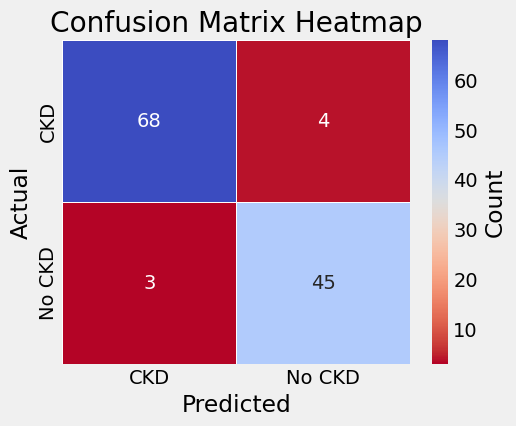

Result,Number,Description
True Positive,68,"Actual occurrence, correctly predicted"
True Negative,45,"Non-occurrence, correctly predicted"
False Negative,4,"Actual occurrence, incorrectly predicted (Type II error)"
False Positive,3,"Non-occurrence, incorrectly predicted (Type I error)"


Metric,Value,Description
Accuracy,94.17%,How often is classifier correct
Precision,95.77%,How often is TP correctly predicted (% of correct positives)
Recall,94.44%,How often is actual occurrence correctly predicted
F1-Score,95.10%,Account for both precision and recall using harmonic mean
Misclassification,5.83%,How often is classifier wrong
NPV,91.84%,How often is TN correctly predicted (% of correct negatives)
FPR,6.25%,How often is non-occurrence falsely predicted
Specificity,93.75%,How often is actual non-occurrence correctly predicted
Prevalence,60.00%,How often does actually occur in sample


In [68]:
# Plot confusion matrix heatmap:
cm_heatmap(cm)

# Show classifier results and metrics:
display(get_cm_results(cm))
display(get_cm_metrics(cm))

# Track results:
save_cm(cm, dtc)

In [69]:
# Hyper parameter tuning of decision tree:

# Input hyper paramter to choose from to find the best estimator to increase the accuracy
# and avoid overfitting of the model:
grid_param = {
    'criterion' : ['gini', 'entropy'],
    'max_depth' : [3, 5, 7, 10],
    'splitter' : ['best', 'random'],
    'min_samples_leaf' : [1, 2, 3, 5, 7],
    'min_samples_split' : [2, 3, 5, 7],
    'max_features' : ['sqrt', 'log2']  # How many input features the tree considers to build the model
}

# Use GridSearchCV to try provided different compbination of hyper parameter:
grid_search_dtc = GridSearchCV(dtc, grid_param, cv = 5, n_jobs = -1, verbose = 1)
grid_search_dtc.fit(X_train, y_train)

Fitting 5 folds for each of 640 candidates, totalling 3200 fits


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 3, 5, 7],
                         'min_samples_split': [2, 3, 5, 7],
                         'splitter': ['best', 'random']},
             verbose=1)

In [70]:
# Best parameters and best score:
print(grid_search_dtc.best_params_)
print(grid_search_dtc.best_score_)

{'criterion': 'gini', 'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'min_samples_split': 2, 'splitter': 'best'}
0.9821428571428571


In [71]:
# Best estimator:
dtc = grid_search_dtc.best_estimator_

# Accuracy score, confusion matrix and classification report of decision tree
dtc_acc = accuracy_score(y_test, dtc.predict(X_test))

print(
    "Training Accuracy of Decision Tree Classifier - Hyperparameter best estimator is "
      f"{accuracy_score(y_train, dtc.predict(X_train))}"
)
print(f"Test Accuracy of Decision Tree Classifier - Hyperparameter best estimator is {dtc_acc} \n")

cm = confusion_matrix(y_test, dtc.predict(X_test))
print(f"Confusion Matrix after hyperparameter tuning :- \n{cm}\n")
print(
    "Classification Report after hyperparameter tuning :- \n "
    f"{classification_report(y_test, dtc.predict(X_test))}"
)

Training Accuracy of Decision Tree Classifier - Hyperparameter best estimator is 0.975
Test Accuracy of Decision Tree Classifier - Hyperparameter best estimator is 0.95 

Confusion Matrix after hyperparameter tuning :- 
[[47  1]
 [ 5 67]]

Classification Report after hyperparameter tuning :- 
               precision    recall  f1-score   support

           0       0.90      0.98      0.94        48
           1       0.99      0.93      0.96        72

    accuracy                           0.95       120
   macro avg       0.94      0.95      0.95       120
weighted avg       0.95      0.95      0.95       120



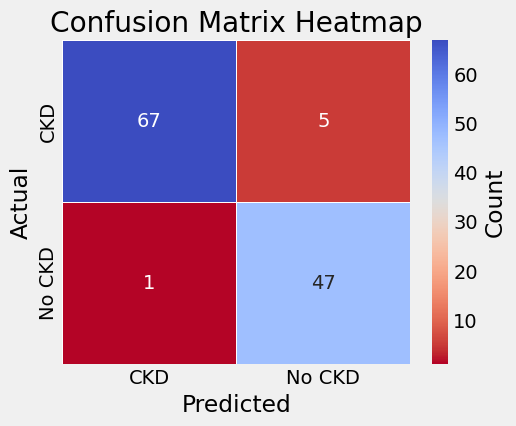

Result,Number,Description
True Positive,67,"Actual occurrence, correctly predicted"
True Negative,47,"Non-occurrence, correctly predicted"
False Negative,5,"Actual occurrence, incorrectly predicted (Type II error)"
False Positive,1,"Non-occurrence, incorrectly predicted (Type I error)"


Metric,Value,Description
Accuracy,95.00%,How often is classifier correct
Precision,98.53%,How often is TP correctly predicted (% of correct positives)
Recall,93.06%,How often is actual occurrence correctly predicted
F1-Score,95.71%,Account for both precision and recall using harmonic mean
Misclassification,5.00%,How often is classifier wrong
NPV,90.38%,How often is TN correctly predicted (% of correct negatives)
FPR,2.08%,How often is non-occurrence falsely predicted
Specificity,97.92%,How often is actual non-occurrence correctly predicted
Prevalence,60.00%,How often does actually occur in sample


In [72]:
# Plot confusion matrix heatmap:
cm_heatmap(cm)

# Show classifier results and metrics:
display(get_cm_results(cm))
display(get_cm_metrics(cm))

# Track results:
save_cm(cm, 'DecisionTreeClassifier-GridSearchCV')

<a id = '5.3'></a>
<p style = "font-size : 25px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #fbc6a4; border-radius: 5px 5px;"><strong>Random Forest Classifier</strong></p>

In [73]:
# Note:  The default for max_features changed from 'auto' to 'sqrt', updating:
# Direct initialization of RandomForestClassifier object for specific hyperparamter value.
# Not using RandomizedSearchCV for the tunning.
rd_clf = RandomForestClassifier(
    criterion = 'entropy', max_depth = 11, max_features = 'sqrt',
    min_samples_leaf = 2, min_samples_split = 3, n_estimators = 130
)
rd_clf.fit(X_train, y_train)

# Accuracy score, confusion matrix and classification report of random forest:
rd_clf_acc = accuracy_score(y_test, rd_clf.predict(X_test))

print(f"Training Accuracy of Random Forest Classifier is {accuracy_score(y_train, rd_clf.predict(X_train))}")
print(f"Test Accuracy of Random Forest Classifier is {rd_clf_acc} \n")

cm = confusion_matrix(y_test, rd_clf.predict(X_test))
print(f"Confusion Matrix :- \n{cm}\n")
print(f"Classification Report :- \n {classification_report(y_test, rd_clf.predict(X_test))}")

Training Accuracy of Random Forest Classifier is 0.9964285714285714
Test Accuracy of Random Forest Classifier is 1.0 

Confusion Matrix :- 
[[48  0]
 [ 0 72]]

Classification Report :- 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        48
           1       1.00      1.00      1.00        72

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



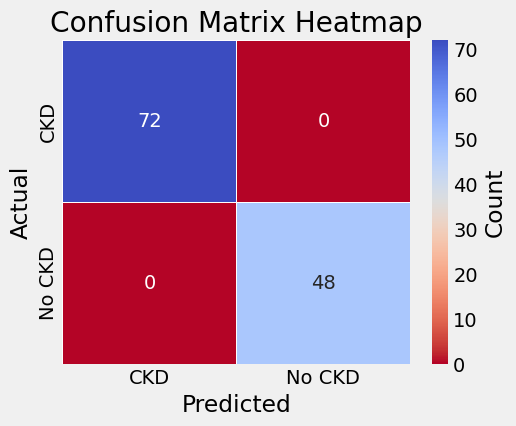

Result,Number,Description
True Positive,72,"Actual occurrence, correctly predicted"
True Negative,48,"Non-occurrence, correctly predicted"
False Negative,0,"Actual occurrence, incorrectly predicted (Type II error)"
False Positive,0,"Non-occurrence, incorrectly predicted (Type I error)"


Metric,Value,Description
Accuracy,100.00%,How often is classifier correct
Precision,100.00%,How often is TP correctly predicted (% of correct positives)
Recall,100.00%,How often is actual occurrence correctly predicted
F1-Score,100.00%,Account for both precision and recall using harmonic mean
Misclassification,0.00%,How often is classifier wrong
NPV,100.00%,How often is TN correctly predicted (% of correct negatives)
FPR,0.00%,How often is non-occurrence falsely predicted
Specificity,100.00%,How often is actual non-occurrence correctly predicted
Prevalence,60.00%,How often does actually occur in sample


In [74]:
# Plot confusion matrix heatmap:
cm_heatmap(cm)

# Show classifier results and metrics:
display(get_cm_results(cm))
display(get_cm_metrics(cm))

# Track results:
save_cm(cm, rd_clf)

<a id = '5.3'></a>
<p style = "font-size : 25px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #fbc6a4; border-radius: 5px 5px;"><strong>XgBoost</strong></p>

In [75]:
# Use of the XGBoost (Extreme Gradient Boosting) algorithm for a binary classification task
xgb = XGBClassifier(objective = 'binary:logistic', learning_rate = 0.5, max_depth = 5, n_estimators = 150)
xgb.fit(X_train, y_train)

# accuracy score, confusion matrix and classification report of xgboost
xgb_acc = accuracy_score(y_test, xgb.predict(X_test))

print(f"Training Accuracy of XgBoost is {accuracy_score(y_train, xgb.predict(X_train))}")
print(f"Test Accuracy of XgBoost is {xgb_acc} \n")

cm = confusion_matrix(y_test, xgb.predict(X_test))
print(f"Confusion Matrix :- \n{cm}\n")
print(f"Classification Report :- \n {classification_report(y_test, xgb.predict(X_test))}")

Training Accuracy of XgBoost is 1.0
Test Accuracy of XgBoost is 0.9916666666666667 

Confusion Matrix :- 
[[47  1]
 [ 0 72]]

Classification Report :- 
               precision    recall  f1-score   support

           0       1.00      0.98      0.99        48
           1       0.99      1.00      0.99        72

    accuracy                           0.99       120
   macro avg       0.99      0.99      0.99       120
weighted avg       0.99      0.99      0.99       120



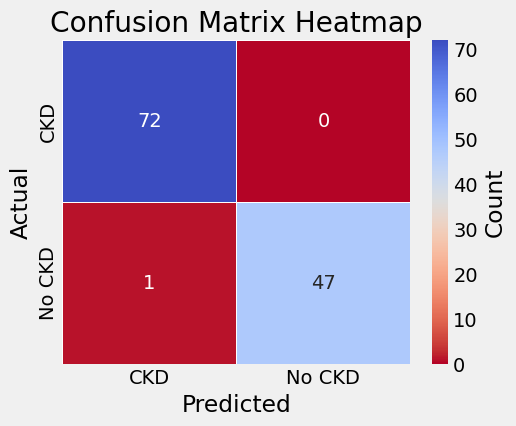

Result,Number,Description
True Positive,72,"Actual occurrence, correctly predicted"
True Negative,47,"Non-occurrence, correctly predicted"
False Negative,0,"Actual occurrence, incorrectly predicted (Type II error)"
False Positive,1,"Non-occurrence, incorrectly predicted (Type I error)"


Metric,Value,Description
Accuracy,99.17%,How often is classifier correct
Precision,98.63%,How often is TP correctly predicted (% of correct positives)
Recall,100.00%,How often is actual occurrence correctly predicted
F1-Score,99.31%,Account for both precision and recall using harmonic mean
Misclassification,0.83%,How often is classifier wrong
NPV,100.00%,How often is TN correctly predicted (% of correct negatives)
FPR,2.08%,How often is non-occurrence falsely predicted
Specificity,97.92%,How often is actual non-occurrence correctly predicted
Prevalence,60.00%,How often does actually occur in sample


In [76]:
# Plot confusion matrix heatmap:
cm_heatmap(cm)

# Show classifier results and metrics:
display(get_cm_results(cm))
display(get_cm_metrics(cm))

# Track results:
save_cm(cm, xgb)

<a id = '5.3'></a>
<p style = "font-size : 25px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #fbc6a4; border-radius: 5px 5px;"><strong>Logistic Regression</strong></p>

In [77]:
# Use of the Logistic Regression algorithm for a binary classification task
# liblinear is good for smaller datasets. For larger datasets, solvers like 'lbfgs'
# or 'saga' may perform better.  This parameter sets the seed for the random number
# generator used by the model. Setting a random_state ensures that the results are
# reproducible. If you run the code multiple times with the same random_state, you'll
# get the same results.
logistic_regression = LogisticRegression(solver='liblinear', random_state=42) 

logistic_regression.fit(X_train, y_train)

# accuracy score, confusion matrix and classification report of logistic regression
logistic_acc = accuracy_score(y_test, logistic_regression.predict(X_test))

print(
    "Training Accuracy of Logistic Regression is "
    f"{accuracy_score(y_train, logistic_regression.predict(X_train))}"
)
print(f"Test Accuracy of Logistic Regression is {logistic_acc} \n")

cm = confusion_matrix(y_test, logistic_regression.predict(X_test))
print(f"Confusion Matrix :- \n{cm}\n")
print(
    "Classification Report :- \n "
    f"{classification_report(y_test, logistic_regression.predict(X_test))}"
)

Training Accuracy of Logistic Regression is 0.9964285714285714
Test Accuracy of Logistic Regression is 0.975 

Confusion Matrix :- 
[[48  0]
 [ 3 69]]

Classification Report :- 
               precision    recall  f1-score   support

           0       0.94      1.00      0.97        48
           1       1.00      0.96      0.98        72

    accuracy                           0.97       120
   macro avg       0.97      0.98      0.97       120
weighted avg       0.98      0.97      0.98       120



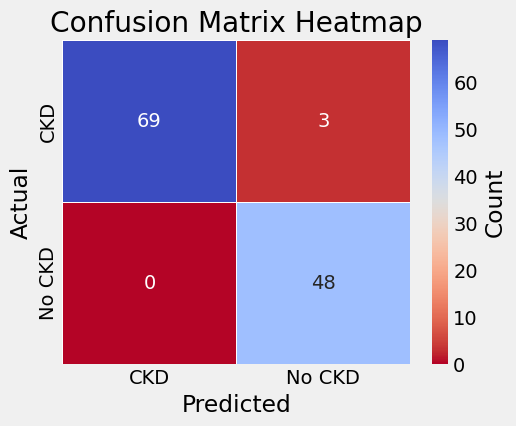

Result,Number,Description
True Positive,69,"Actual occurrence, correctly predicted"
True Negative,48,"Non-occurrence, correctly predicted"
False Negative,3,"Actual occurrence, incorrectly predicted (Type II error)"
False Positive,0,"Non-occurrence, incorrectly predicted (Type I error)"


Metric,Value,Description
Accuracy,97.50%,How often is classifier correct
Precision,100.00%,How often is TP correctly predicted (% of correct positives)
Recall,95.83%,How often is actual occurrence correctly predicted
F1-Score,97.87%,Account for both precision and recall using harmonic mean
Misclassification,2.50%,How often is classifier wrong
NPV,94.12%,How often is TN correctly predicted (% of correct negatives)
FPR,0.00%,How often is non-occurrence falsely predicted
Specificity,100.00%,How often is actual non-occurrence correctly predicted
Prevalence,60.00%,How often does actually occur in sample


In [78]:
# Plot confusion matrix heatmap:
cm_heatmap(cm)

# Show classifier results and metrics:
display(get_cm_results(cm))
display(get_cm_metrics(cm))

# Track results:
save_cm(cm, logistic_regression)

<a id = '6.0'></a>
<p style = "font-size : 35px; color : #34656d ; font-family : 'Comic Sans MS'; text-align : center; background-color : #f9b208; border-radius: 5px 5px;"><strong>Models Comparison</strong></p> 

In [79]:
models = pd.DataFrame({
    'Model' : ['Decision Tree Classifier', 'Random Forest Classifier', 'XgBoost', 'Logistic Regression'],
    'Score' : [dtc_acc, rd_clf_acc, xgb_acc, logistic_acc]
})

models.sort_values(by='Score', ascending=False)

,Model,Score
1,Random Forest Classifier,1.000000
2,XgBoost,0.991667
3,Logistic Regression,0.975000
0,Decision Tree Classifier,0.950000


In [80]:
# Flip sort order to show best model at the top:
models_sorted = models.sort_values(by='Score', ascending=True)

fig = px.bar(
    data_frame=models_sorted,
    x='Score',
    y='Model',
    color='Score',
    template='plotly_dark',
    title='Models Comparison'
)
fig.show()

### Select XGBoost model - more reliable:

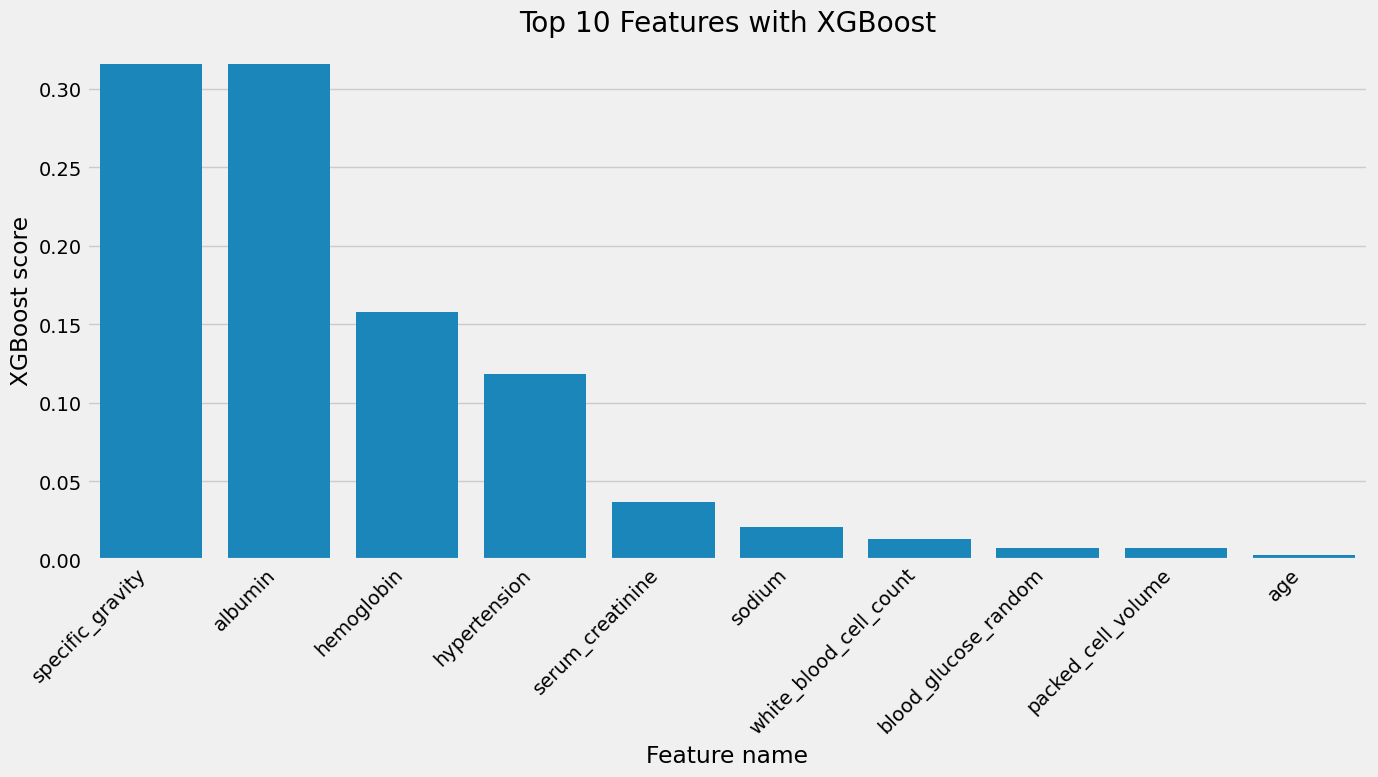

In [ ]:
# Top 10 Features:
feature_scores = pd.DataFrame(
    xgb.feature_importances_, columns=['Score'], index=X_train.columns
).sort_values(by='Score', ascending=False)
top10_features = feature_scores.nlargest(n=10, columns=['Score'])

plt.figure(figsize=(14, 8))
g = sns.barplot(x=top10_features.index, y=top10_features['Score'])
p = plt.title('Top 10 Features with XGBoost')
p = plt.xlabel('Feature name')
p = plt.ylabel('XGBoost score')

# Rotate x-axis tick labels
for tick in g.get_xticklabels():
    tick.set_rotation(45)
    tick.set_horizontalalignment('right')

plt.tight_layout()
plt.show()

In [82]:
top10_features = top10_features.index.tolist()
top10_features

['specific_gravity',
 'albumin',
 'hemoglobin',
 'hypertension',
 'serum_creatinine',
 'sodium',
 'white_blood_cell_count',
 'blood_glucose_random',
 'packed_cell_volume',
 'age']

In [83]:
# Current columns:
X.columns

Index(['age', 'blood_pressure', 'specific_gravity', 'albumin', 'sugar',
       'red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria',
       'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
       'potassium', 'hemoglobin', 'packed_cell_volume',
       'white_blood_cell_count', 'red_blood_cell_count', 'hypertension',
       'diabetes_mellitus', 'coronary_artery_disease', 'appetite',
       'peda_edema', 'anemia'],
      dtype='object')

In [84]:
# Prune columns not in top 10:
for ele in X.columns:
    if ele not in top10_features:
        X = X.drop(ele, axis = 1)

# Display:
X.head()

,age,specific_gravity,albumin,blood_glucose_random,serum_creatinine,sodium,hemoglobin,packed_cell_volume,white_blood_cell_count,hypertension
0,48.0,1.020,1.0,121.000000,1.2,137.528754,15.4,44.0,7800.0,1
1,7.0,1.020,4.0,148.036517,0.8,137.528754,11.3,38.0,6000.0,0
2,62.0,1.010,2.0,423.000000,1.8,137.528754,9.6,31.0,7500.0,0
3,48.0,1.005,4.0,117.000000,3.8,111.000000,11.2,32.0,6700.0,1
4,51.0,1.010,2.0,106.000000,1.4,137.528754,11.6,35.0,7300.0,0


In [85]:
X_train=X_train[top10_features]
X_test=X_test[top10_features]
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.5, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

### Testing Predictions:

In [86]:
# Prediction 1 - CKD:

# Patient ID=249:
patient_data = {
    'specific_gravity': 1.01,
    'albumin': 4,
    'hemoglobin': 3.1,
    'hypertension': 1,
    'serum_creatinine': 13.3,
    'sodium': 124,
    'white_blood_cell_count': 5400,
    'blood_glucose_random': 176,
    'packed_cell_volume': 9,
    'age': 56
}
prediction = xgb.predict(pd.DataFrame([patient_data]))[0]

if prediction:
    print('Unfortunately, you have Chronic Kidney Disease.')
else:
    print("Fortunately, you don't have Chronic Kidney Disease.")

Unfortunately, you have Chronic Kidney Disease.


In [87]:
# Prediction 2 - No CKD:

# Patient ID=250
patient_data = {
    'specific_gravity': 1.025,
    'albumin': 0,
    'hemoglobin': 15,
    'hypertension': 0,
    'serum_creatinine': 1.2,
    'sodium': 135,
    'white_blood_cell_count': 10400,
    'blood_glucose_random': 140,
    'packed_cell_volume': 48,
    'age': 40
}
prediction = xgb.predict(pd.DataFrame([patient_data]))[0]

if prediction:
    print('Unfortunately, you have Chronic Kidney Disease.')
else:
    print("Fortunately, you don't have Chronic Kidney Disease.")

Fortunately, you don't have Chronic Kidney Disease.


### Serialize and save model:

In [88]:
pickle.dump(xgb, open('CKD-XGB-UCI.pkl', 'wb'))